# Rolling Hurst Exponent — S&P 500 prices in DuckDB

**What this notebook does:** reads your OHLCV table from a local `.duckdb` file (read-only, nothing is written back), computes the **rolling Hurst exponent** of log returns at **126 / 252 / 504 trading days** for **every ticker**, and plots how persistence evolves over time and across the universe.

## How to read the Hurst exponent $H$

| $H$ | Behaviour of the return series |
|---|---|
| $H \approx 0.5$ | Random walk — past returns tell you nothing about future returns |
| $H > 0.5$ | **Persistent** — up moves tend to be followed by up moves (trending/momentum-like) |
| $H < 0.5$ | **Anti-persistent** — up moves tend to reverse (mean-reverting-like) |

⚠️ **Two traps this notebook is designed around:**

1. **The textbook R/S estimator is biased upward on short windows.** Pure noise reads ≈ 0.58–0.61, not 0.5. We therefore use the **Anis–Lloyd (1976) finite-sample correction** (each scale's R/S divided by its expected value under white noise) and, in §3, simulate **window-specific random-walk bands**. Judge a ticker against its band, not against a hard 0.5 line. Set `CORRECTED = False` in the config to reproduce textbook values (e.g. to match other libraries — expect them to run ~0.08 higher).
2. **Hurst is a description, not a forecast.** A 252-day $H$ of 0.6 says the *past year* was persistent; overlapping rolling windows make $H$ itself look smooth and "predictable" — that smoothness is mechanical (250 of 252 returns are shared day to day), not signal.

Method in one line: for each window of daily log returns, split it into blocks of length $n$, compute the rescaled range $R/S$ of each block, average, and take $H$ as the slope of $\log(R/S)$ vs $\log(n)$ over 8 log-spaced scales from 10 to $\text{window}/2$. §7 plots that regression so you can see what a single $H$ summarises.

## 0 · Config — point this at your laptop's database

In [1]:
from pathlib import Path
import subprocess, sys, time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import rolling_hurst as rh

# ---------------------------------------------------------------- config --
# >>> EDIT THIS LINE: path to YOUR DuckDB file, e.g.
#     Path(r"C:\data\sp500.duckdb")        (Windows)
#     Path("~/data/sp500.duckdb").expanduser()   (Mac / Linux)
DB_PATH = Path("sp500.duckdb")

# Table/column overrides: leave as None to auto-detect (ticker/date/adj-close
# style columns in an OHLCV table are found automatically, case-insensitive).
TABLE = TICKER_COL = DATE_COL = PRICE_COL = None   # e.g. TABLE="daily_bars", PRICE_COL="close"

WINDOWS = (126, 252, 504)   # trading days of log returns (~6m / 1y / 2y)
STEP = 5                    # one Hurst point every 5 trading days (weekly).
                            # STEP=1 is fine with numba, rarely more informative.
CORRECTED = True            # Anis-Lloyd correction (see intro). False = textbook R/S.
TICKER_TO_PLOT = "AAPL"     # falls back automatically if not in your DB
EXPORT_CSV = False          # notebook-only by default; True also saves rolling_hurst.csv
# ---------------------------------------------------------------------------

# If your file isn't there yet, build a synthetic demo DB so the notebook
# still runs top-to-bottom (clearly fake data - DEMO_* and SYN* tickers).
if not DB_PATH.exists():
    demo = Path("demo_sp500.duckdb")
    if not demo.exists():
        print(f"{DB_PATH} not found -> creating synthetic demo DB ...")
        subprocess.run([sys.executable, "make_demo_duckdb.py", "--out", str(demo)], check=True)
    DB_PATH = demo
    print(f"*** Using DEMO database {demo} - set DB_PATH above to your real file. ***")
else:
    print(f"Using your database: {DB_PATH}")

print(f"numba acceleration: {'ON' if rh.HAS_NUMBA else 'off (pip install numba for ~100x speedup)'}")
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

*** Using DEMO database demo_sp500.duckdb - set DB_PATH above to your real file. ***
numba acceleration: ON


## 1 · Inspect the database (auto-detected schema)

In [2]:
schema = rh.discover_price_schema(DB_PATH, table=TABLE, ticker_col=TICKER_COL,
                                  date_col=DATE_COL, price_col=PRICE_COL)
print(schema)
print("\nPrice column actually used:", schema.price_col,
      "  <- adjusted close is preferred on purpose: splits/dividends in a raw\n"
      "     close appear as huge one-day 'reversals' and drag H down spuriously." if "adj" in schema.price_col.lower()
      else "\n     (no adjusted-close column found - H around splits/dividends will be distorted)")

# Quick inventory straight from DuckDB
import duckdb
con = duckdb.connect(str(DB_PATH), read_only=True)
inv = con.execute(
    f'SELECT COUNT(*) AS n_rows, COUNT(DISTINCT "{schema.ticker_col}") AS tickers, '
    f'MIN(CAST("{schema.date_col}" AS DATE)) AS first_date, MAX(CAST("{schema.date_col}" AS DATE)) AS last_date '
    f'FROM "{schema.table}"'
).fetchdf() if schema.ticker_col else None
con.close()
inv

table='prices'  ticker_col='ticker'  date_col='date'  price_col='adj_close'
all columns: ['ticker', 'date', 'open', 'high', 'low', 'close', 'adj_close', 'volume']
other candidate tables seen: ['prices']

Price column actually used: adj_close   <- adjusted close is preferred on purpose: splits/dividends in a raw
     close appear as huge one-day 'reversals' and drag H down spuriously.


,n_rows,tickers,first_date,last_date
0,78270,30,2015-01-01,2024-12-31


## 2 · Load prices and check data quality

`load_prices` standardises everything to `ticker, date, price`, sorts, de-duplicates `(ticker, date)`, and drops non-positive prices. Windows later count *observations per ticker*, so tickers with short histories simply contribute to fewer windows.

In [3]:
prices = rh.load_prices(DB_PATH, table=TABLE, ticker_col=TICKER_COL,
                        date_col=DATE_COL, price_col=PRICE_COL)
obs = prices.groupby("ticker").size().rename("n_prices")
print(f"{len(prices):,} rows | {prices.ticker.nunique()} tickers | "
      f"{prices.date.min().date()} -> {prices.date.max().date()}")
print(f"Tickers long enough for each window (need window+1 prices):")
for w in WINDOWS:
    print(f"  {w:>3}d: {(obs > w).sum():>4} tickers")
obs.describe().round(0)

78,270 rows | 30 tickers | 2015-01-01 -> 2024-12-31
Tickers long enough for each window (need window+1 prices):
  126d:   30 tickers
  252d:   30 tickers
  504d:   30 tickers


count      30.000
mean    2,609.000
std         0.000
min     2,609.000
25%     2,609.000
50%     2,609.000
75%     2,609.000
max     2,609.000
Name: n_prices, dtype: float64

In [4]:
prices.head(8)

,ticker,date,price
0,DEMO_MEANREV,2015-01-01,100.000
1,DEMO_MEANREV,2015-01-02,99.220
2,DEMO_MEANREV,2015-01-05,100.569
3,DEMO_MEANREV,2015-01-06,101.152
4,DEMO_MEANREV,2015-01-07,101.449
5,DEMO_MEANREV,2015-01-08,102.108
6,DEMO_MEANREV,2015-01-09,99.854
7,DEMO_MEANREV,2015-01-12,101.595


## 3 · Validate the estimator before trusting it on real data

We simulate fractional Gaussian noise with **known** true $H \in \{0.3,\ 0.5,\ 0.8\}$ and check what the estimator recovers at each window — first with the Anis–Lloyd correction, then textbook R/S for contrast. This is the single most important sanity check in the notebook: it tells you how much of what you'll see later is estimator bias vs. actual market behaviour.

Expect the corrected estimator to be centred on ~0.5 for noise and **compressed toward 0.5** at the extremes (true 0.8 → ≈ 0.7). R/S is a regime *ranking* device, not a precision instrument.

In [5]:
rng = np.random.default_rng(123)
REPS = 40
sim = {h: [rh.simulate_fgn(1024, h, rng) for _ in range(REPS)] for h in (0.3, 0.5, 0.8)}

def mean_est(reps, w, corrected):
    return np.mean([rh.rolling_hurst(x[:w], window=w, step=w, corrected=corrected)[1][0] for x in reps])

rows = []
for h_true, reps in sim.items():
    row = {"true H": h_true}
    for w in WINDOWS:
        row[f"corrected {w}d"] = mean_est(reps, w, True)
    row["textbook 252d"] = mean_est(reps, 252, False)
    rows.append(row)
validation = pd.DataFrame(rows).set_index("true H").round(3)
print("Mean estimated H over", REPS, "simulated series per row:")
validation

Mean estimated H over 40 simulated series per row:


,corrected 126d,corrected 252d,corrected 504d,textbook 252d
true H,,,,
0.300,0.352,0.339,0.344,0.430
0.500,0.472,0.485,0.489,0.577
0.800,0.644,0.664,0.707,0.756


In [6]:
# Random-walk null bands per window: distribution of estimated H when
# returns are pure white noise. Use THESE bands to judge real tickers.
null_bands = rh.white_noise_null_bands(WINDOWS, n_sims=300, corrected=CORRECTED, seed=42)
band = {int(r.window): (r.q05, r.q95) for r in null_bands.itertuples()}
print("If a stock were a pure random walk, its estimated H would fall between q05 and q95 90% of the time:")
null_bands.round(3)

If a stock were a pure random walk, its estimated H would fall between q05 and q95 90% of the time:


,window,mean,std,q05,q50,q95
0,126,0.481,0.089,0.351,0.473,0.630
1,252,0.495,0.065,0.398,0.493,0.601
2,504,0.494,0.048,0.419,0.494,0.575


## 4 · Compute rolling Hurst for the whole universe

Windows count **log returns** (a 252 window = last 252 daily log returns = 253 prices), each value is stamped with the **last date inside its window** (no look-ahead), and with `STEP = 5` you get a weekly Hurst path per ticker. With numba, 500 tickers × 10 years × 3 windows takes well under a minute; without it, keep `STEP=5` (or 21).

In [7]:
t0 = time.perf_counter()
hurst = rh.compute_rolling_hurst(prices, windows=WINDOWS, step=STEP, corrected=CORRECTED)
print(f"\nDone in {time.perf_counter()-t0:.1f}s -> {len(hurst):,} rows")
hurst.head(10)

Rolling Hurst: 30 tickers x windows=(126, 252, 504) x step=5 (numba=on)
  30/30 tickers done

Done in 0.2s -> 14,880 rows


,ticker,date,hurst_126,hurst_252,hurst_504
0,DEMO_MEANREV,2015-07-02,0.301,NaN,NaN
1,DEMO_MEANREV,2015-07-09,0.342,NaN,NaN
2,DEMO_MEANREV,2015-07-16,0.337,NaN,NaN
3,DEMO_MEANREV,2015-07-23,0.374,NaN,NaN
4,DEMO_MEANREV,2015-07-30,0.384,NaN,NaN
5,DEMO_MEANREV,2015-08-06,0.353,NaN,NaN
6,DEMO_MEANREV,2015-08-13,0.328,NaN,NaN
7,DEMO_MEANREV,2015-08-20,0.337,NaN,NaN
8,DEMO_MEANREV,2015-08-27,0.385,NaN,NaN
9,DEMO_MEANREV,2015-09-03,0.359,NaN,NaN


## 5 · The market as a whole: median Hurst across all tickers

A cross-sectional median is a robust "regime gauge": when the median stock drifts above its random-walk band, persistence was broad-based (not one meme stock). Remember the caveat from §3 — with 504-day windows the gauge moves slowly by construction.

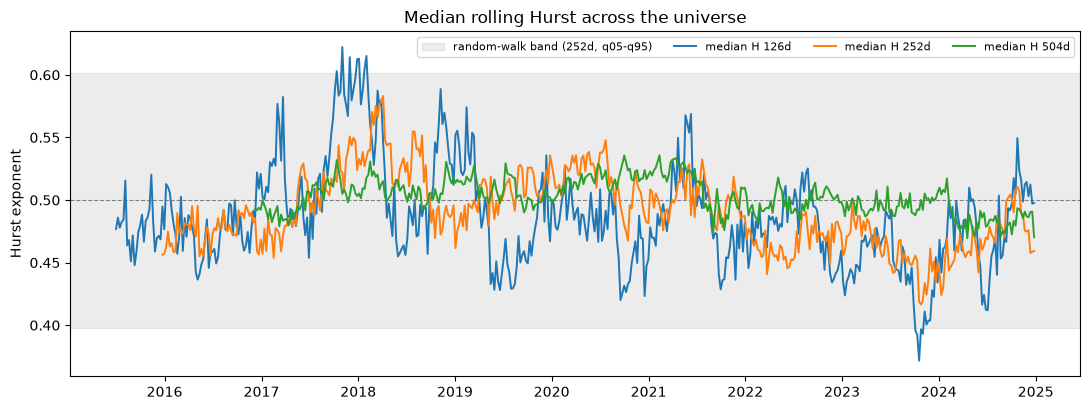

In [8]:
median_h = hurst.groupby("date")[[f"hurst_{w}" for w in WINDOWS]].median()

fig, ax = plt.subplots(figsize=(11, 4.2))
lo, hi = band[252]
ax.axhspan(lo, hi, color="grey", alpha=0.15, label="random-walk band (252d, q05-q95)")
ax.axhline(0.5, color="grey", lw=0.8, ls="--")
for w in WINDOWS:
    ax.plot(median_h.index, median_h[f"hurst_{w}"], lw=1.4, label=f"median H {w}d")
ax.set_ylabel("Hurst exponent"); ax.set_title("Median rolling Hurst across the universe"); ax.legend(ncol=4, fontsize=8)
plt.tight_layout(); plt.show()

## 6 · Breadth: share of tickers in each regime (252d)

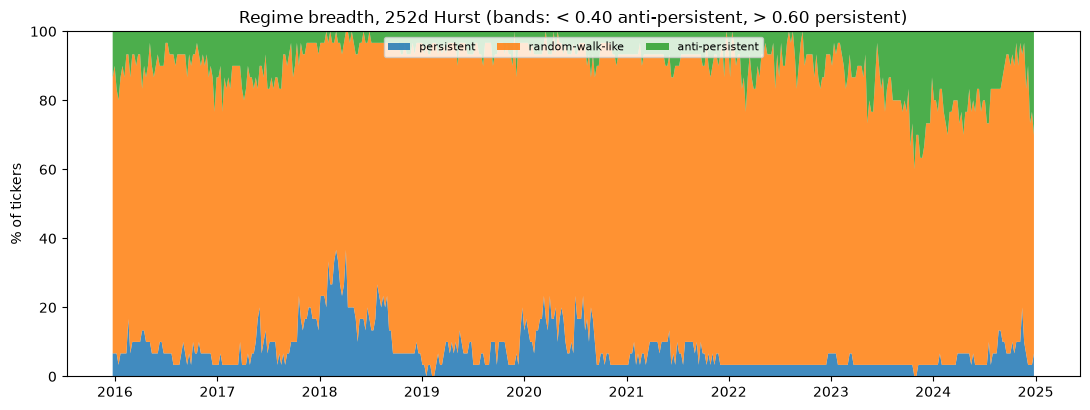

Note: by construction ~90% of pure-noise tickers would sit in 'random-walk-like'.
Persistent shares persistently >>5% are the actual signal here.


In [9]:
lo, hi = band[252]
def regime(h):
    return np.where(h > hi, "persistent", np.where(h < lo, "anti-persistent", "random-walk-like"))

share = (hurst.dropna(subset=["hurst_252"])
         .assign(regime=lambda d: regime(d["hurst_252"]))
         .groupby(["date", "regime"]).size().unstack(fill_value=0))
share = share.div(share.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(11, 4.2))
order = [c for c in ["persistent", "random-walk-like", "anti-persistent"] if c in share]
ax.stackplot(share.index, [share[c] for c in order], labels=order, alpha=0.85)
ax.set_ylabel("% of tickers"); ax.set_ylim(0, 100)
ax.set_title(f"Regime breadth, 252d Hurst (bands: < {lo:.2f} anti-persistent, > {hi:.2f} persistent)")
ax.legend(fontsize=8, loc="upper center", ncol=3)
plt.tight_layout(); plt.show()
print("Note: by construction ~90% of pure-noise tickers would sit in 'random-walk-like'.\n"
      "Persistent shares persistently >>5% are the actual signal here.")

## 7 · Single-ticker explorer

Price (log scale) on top, its three rolling Hurst paths below, plus the inside of one Hurst calculation: the $\log(R/S)$ vs $\log(n)$ scaling plot for the latest 504-day window. If those eight points do not sit roughly on a straight line, treat that window's $H$ with suspicion — a single slope is a poor summary of a kinked scaling curve (common around crashes, when short scales and long scales behave differently).

Plotting: DEMO_PERSIST


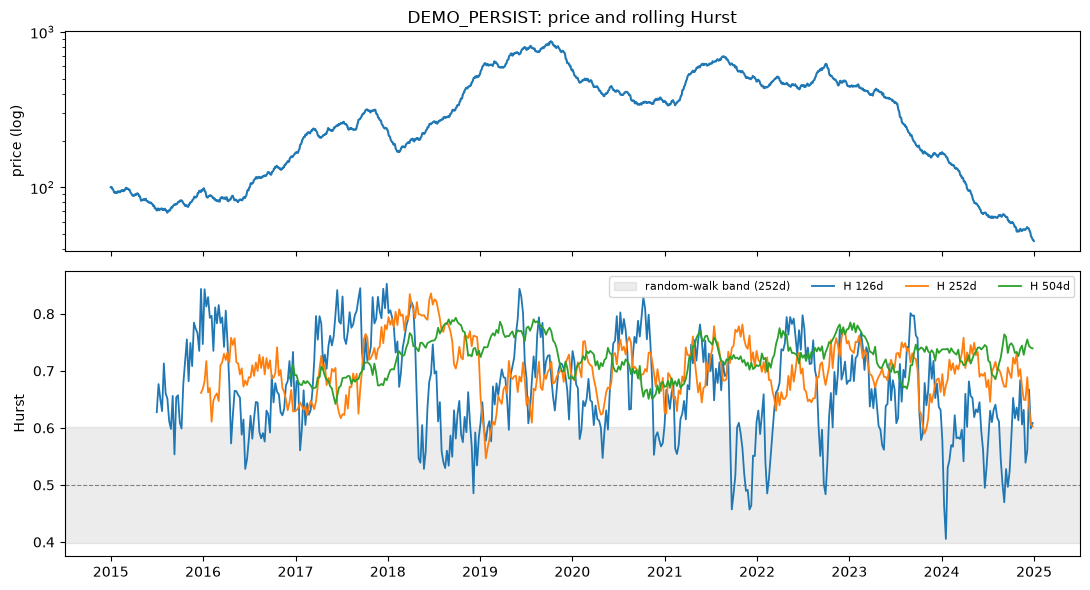

In [10]:
available = set(hurst.dropna(subset=[f"hurst_{max(WINDOWS)}"])["ticker"])
ticker = TICKER_TO_PLOT if TICKER_TO_PLOT in available else (
    "DEMO_PERSIST" if "DEMO_PERSIST" in available else sorted(available)[0])
print("Plotting:", ticker)

px = prices[prices.ticker == ticker].set_index("date")["price"]
hh = hurst[hurst.ticker == ticker].set_index("date")

fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True,
                             gridspec_kw={"height_ratios": [1, 1.3]})
a1.plot(px.index, px); a1.set_yscale("log"); a1.set_ylabel("price (log)")
a1.set_title(f"{ticker}: price and rolling Hurst")
lo, hi = band[252]
a2.axhspan(lo, hi, color="grey", alpha=0.15, label="random-walk band (252d)")
a2.axhline(0.5, color="grey", lw=0.8, ls="--")
for w in WINDOWS:
    a2.plot(hh.index, hh[f"hurst_{w}"], lw=1.3, label=f"H {w}d")
a2.set_ylabel("Hurst"); a2.legend(fontsize=8, ncol=4)
plt.tight_layout(); plt.show()

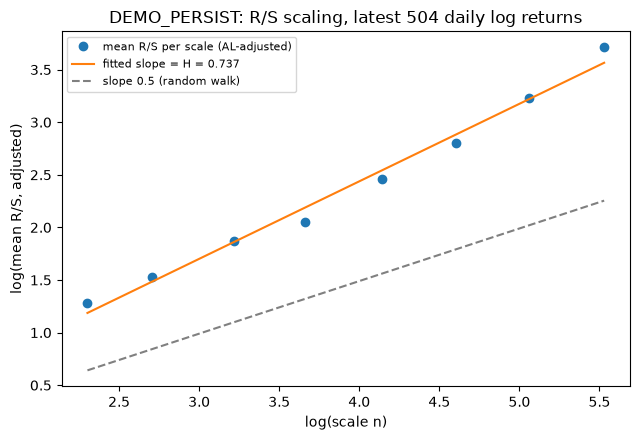

scales used: [ 10  15  25  39  63 100 158 252]


In [11]:
# Inside one window: the scaling regression behind a single H value
log_ret = np.diff(np.log(px.to_numpy()))
det = rh.hurst_rs_details(log_ret[-504:], corrected=CORRECTED)

fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.plot(det["log_scales"], det["log_rs_adjusted"], "o", label="mean R/S per scale (AL-adjusted)")
ax.plot(det["log_scales"], det["intercept"] + det["hurst"] * det["log_scales"],
        "-", label=f"fitted slope = H = {det['hurst']:.3f}")
ax.plot(det["log_scales"], det["intercept"] + 0.5 * det["log_scales"],
        "--", color="grey", label="slope 0.5 (random walk)")
ax.set_xlabel("log(scale n)"); ax.set_ylabel("log(mean R/S, adjusted)")
ax.set_title(f"{ticker}: R/S scaling, latest 504 daily log returns"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"scales used: {det['scales']}")

## 8 · Latest snapshot: most persistent / most anti-persistent tickers

Sorted by the most recent 252-day value. **Read with §3's bands in hand:** with ~500 tickers, the top of this table is *guaranteed* to look extreme even if every stock were a random walk (multiple-comparisons effect — the maximum of 500 draws from the null distribution sits far above its 95th percentile). This table is a screening device for further study, **not** a buy list.

Random-walk band (252d): 0.398 - 0.601 | as of 2024-12-26


ticker,as_of,hurst,regime
SYN003,2024-12-26 00:00:00,0.610,persistent
DEMO_PERSIST,2024-12-26 00:00:00,0.603,persistent
SYN021,2024-12-26 00:00:00,0.591,random-walk-like
DEMO_RW,2024-12-26 00:00:00,0.559,random-walk-like
SYN012,2024-12-26 00:00:00,0.536,random-walk-like
SYN006,2024-12-26 00:00:00,0.527,random-walk-like
SYN001,2024-12-26 00:00:00,0.527,random-walk-like
SYN002,2024-12-26 00:00:00,0.493,random-walk-like
SYN017,2024-12-26 00:00:00,0.490,random-walk-like
SYN018,2024-12-26 00:00:00,0.489,random-walk-like


ticker,as_of,hurst,regime
SYN007,2024-12-26 00:00:00,0.453,random-walk-like
SYN016,2024-12-26 00:00:00,0.451,random-walk-like
SYN004,2024-12-26 00:00:00,0.428,random-walk-like
SYN023,2024-12-26 00:00:00,0.423,random-walk-like
SYN026,2024-12-26 00:00:00,0.422,random-walk-like
SYN010,2024-12-26 00:00:00,0.420,random-walk-like
SYN020,2024-12-26 00:00:00,0.391,anti-persistent
SYN011,2024-12-26 00:00:00,0.386,anti-persistent
SYN015,2024-12-26 00:00:00,0.381,anti-persistent
SYN005,2024-12-26 00:00:00,0.375,anti-persistent


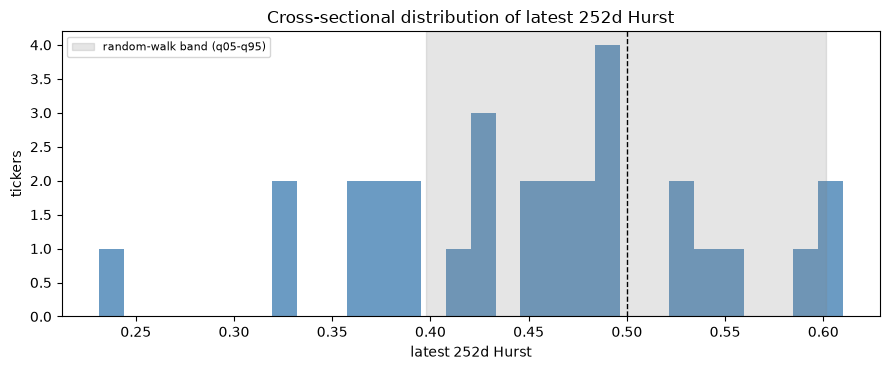

In [12]:
snap = rh.latest_snapshot(hurst, window=252)
lo, hi = band[252]
snap["regime"] = regime(snap["hurst"])
print(f"Random-walk band (252d): {lo:.3f} - {hi:.3f} | as of {snap.as_of.max().date()}")
display(snap.head(15).style.format({"hurst": "{:.3f}"}).hide(axis="index"))
display(snap.tail(15).style.format({"hurst": "{:.3f}"}).hide(axis="index"))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.hist(snap["hurst"], bins=30, color="steelblue", alpha=0.8)
ax.axvspan(lo, hi, color="grey", alpha=0.2, label="random-walk band (q05-q95)")
ax.axvline(0.5, color="k", ls="--", lw=1)
ax.set_xlabel("latest 252d Hurst"); ax.set_ylabel("tickers")
ax.set_title("Cross-sectional distribution of latest 252d Hurst"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## 9 · Caveats worth re-reading before drawing conclusions

* **Survivorship bias** — if your DB holds *today's* S&P 500 list backfilled through history, delisted losers are missing and long-window persistence is flattered. Point-in-time constituents fix this; almost nobody's laptop DB has them. At minimum, don't compare $H$ across decades as if the universe were constant.
* **Adjusted vs raw close** — one 4:1 split in a raw-close series looks like a −75% day followed by "reversal". This notebook prefers adjusted close automatically; check §1's output.
* **Observation-count windows** — a 504 window is the last 504 returns *present in your DB* for that ticker. Halts, missing rows or a listing mid-sample stretch/shrink the calendar span per ticker.
* **Overlapping windows** — successive $H$ values share almost all their data. Smooth Hurst "trends" and slow regime flips are partly arithmetic, not discovery.
* **Volatility clustering ≠ persistence** — GARCH-type returns can nudge R/S estimates. $H>0.5$ is evidence of *some* departure from iid noise, not proof of exploitable momentum.
* **Estimator compression** — §3 showed true $H=0.8$ reads back as ≈ 0.7. Compare tickers/windows *relative to the same estimator and bands*, never to textbook universals.

### Optional export
The notebook is the deliverable and your DuckDB file is opened read-only throughout. If you want the table elsewhere, flip `EXPORT_CSV = True` in §0 (or `hurst.to_parquet(...)` / write it to a *separate* DuckDB file) — re-run the cell below.

In [13]:
if EXPORT_CSV:
    out = Path("rolling_hurst.csv")
    hurst.to_csv(out, index=False)
    print("saved", out.resolve())
else:
    print("EXPORT_CSV=False - results live in the `hurst` DataFrame only (source DB untouched).")

EXPORT_CSV=False - results live in the `hurst` DataFrame only (source DB untouched).
